In [6]:
from google.colab import files

uploaded = files.upload()

Saving ted_talks_cleaned.csv to ted_talks_cleaned.csv


In [9]:
import pandas as pd
import numpy as np
import re
import html

print("Libraries imported successfully!")

Libraries imported successfully!


In [11]:
df = pd.read_csv("/content/ted_talks_cleaned.csv")

print("Dataset loaded successfully!")
print("Original shape:", df.shape)

df.head()

Dataset loaded successfully!
Original shape: (4005, 20)


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript,combined_text
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre...",Averting the climate crisis ['alternative ener...
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac...","The best stats you've ever seen ['Africa', 'As..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun...","Simplicity sells ['computers', 'entertainment'..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...,"Greening the ghetto ['MacArthur grant', 'activ..."
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...,"Do schools kill creativity? ['children', 'crea..."


Unique topics: 457
Top 15 topics:
topic_list
science          993
technology       979
culture          680
TEDx             581
global issues    574
TED-Ed           563
society          557
design           518
social change    512
animation        487
business         443
health           442
history          406
education        390
humanity         388
Name: count, dtype: int64


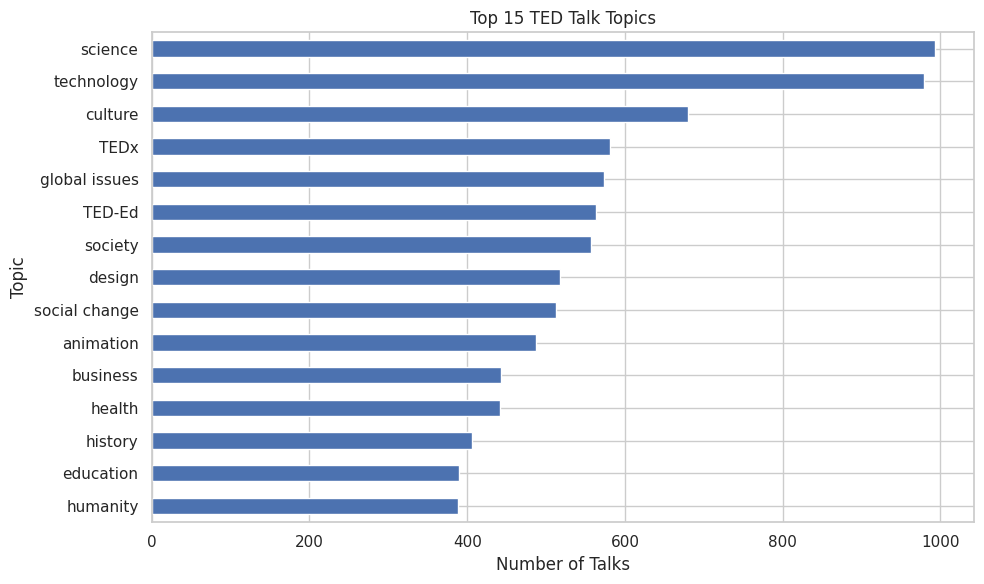

In [12]:
import ast
import pandas as pd
import matplotlib.pyplot as plt

def parse_list_column(value):
    if pd.isna(value):
        return []

    if isinstance(value, list):
        return value

    value = str(value).strip()

    try:
        result = ast.literal_eval(value)
        if isinstance(result, list):
            return result
        return [result] if result else []
    except (ValueError, SyntaxError):
        return [x.strip() for x in value.split(",") if x.strip()]

if "topics" in df.columns:
    df["topic_list"] = df["topics"].apply(parse_list_column)
    df["topic_count"] = df["topic_list"].apply(len)

    topic_counts = (
        df["topic_list"]
        .explode()
        .dropna()
        .astype(str)
        .str.strip()
    )

    topic_counts = topic_counts[topic_counts != ""].value_counts()

    print("Unique topics:", len(topic_counts))
    print("Top 15 topics:")
    print(topic_counts.head(15))

    topic_counts.head(15).sort_values().plot(
        kind="barh", figsize=(10, 6)
    )
    plt.title("Top 15 TED Talk Topics")
    plt.xlabel("Number of Talks")
    plt.ylabel("Topic")
    plt.tight_layout()
    plt.show()
else:
    print("The 'topics' column was not found.")
    print("Available columns:", df.columns.tolist())

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Check whether the speaker column exists
if "speaker_1" in df.columns:

    df["speaker_1"] = df["speaker_1"].fillna("").astype(str).str.strip()

    # Remove empty speaker names
    speakers = df[df["speaker_1"] != ""]

    # Count talks by speaker
    speaker_counts = speakers["speaker_1"].value_counts()

    print("Total unique speakers:", speakers["speaker_1"].nunique())

    print("\nTop 10 speakers:")
    print(speaker_counts.head(10))

else:
    print("speaker_1 column not found.")

Total unique speakers: 3274

Top 10 speakers:
speaker_1
Alex Gendler        34
Iseult Gillespie    19
Emma Bryce          12
Daniel Finkel       11
Alex Rosenthal      10
Hans Rosling        10
Greg Gage            9
Juan Enriquez        9
Chris Anderson       8
Dan Ariely           7
Name: count, dtype: int64


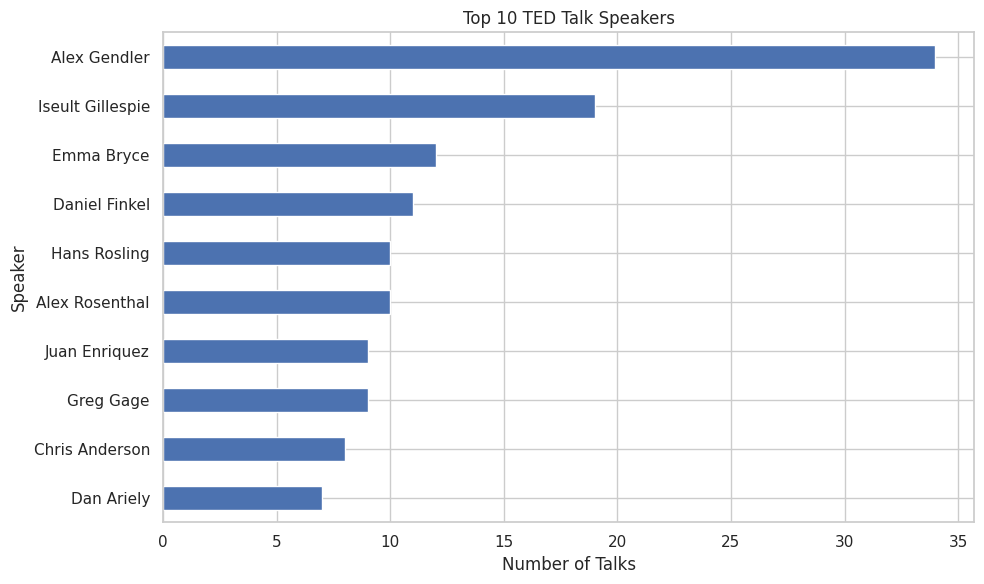

In [14]:
if "speaker_1" in df.columns:

    top_speakers = speaker_counts.head(10).sort_values()

    top_speakers.plot(
        kind="barh",
        figsize=(10, 6)
    )

    plt.title("Top 10 TED Talk Speakers")
    plt.xlabel("Number of Talks")
    plt.ylabel("Speaker")
    plt.tight_layout()
    plt.show()

In [15]:
multiple_talks = speaker_counts[speaker_counts > 1]

print("Speakers with multiple talks:", len(multiple_talks))

print("\nTop repeat speakers:")
print(multiple_talks.head(15))

Speakers with multiple talks: 424

Top repeat speakers:
speaker_1
Alex Gendler        34
Iseult Gillespie    19
Emma Bryce          12
Daniel Finkel       11
Alex Rosenthal      10
Hans Rosling        10
Greg Gage            9
Juan Enriquez        9
Chris Anderson       8
Dan Ariely           7
Marco Tempest        7
Rives                6
Stewart Brand        6
Joy Lin              6
Bill Gates           6
Name: count, dtype: int64


In [16]:
text_columns = [
    "title",
    "description",
    "transcript",
    "about_speakers"
]

for col in text_columns:
    if col in df.columns:
        df[col] = df[col].fillna("").astype(str)
        df[col + "_word_count"] = df[col].apply(
            lambda x: len(x.split())
        )

        print(f"\n{col} word-count statistics:")
        print(df[col + "_word_count"].describe())


title word-count statistics:
count    4005.000000
mean        6.735331
std         2.438527
min         1.000000
25%         5.000000
50%         6.000000
75%         8.000000
max        17.000000
Name: title_word_count, dtype: float64

description word-count statistics:
count    4005.000000
mean       58.195506
std        19.430348
min         9.000000
25%        43.000000
50%        57.000000
75%        72.000000
max       143.000000
Name: description_word_count, dtype: float64

transcript word-count statistics:
count     4005.000000
mean      1796.845693
std       1004.008431
min          2.000000
25%        928.000000
50%       1753.000000
75%       2445.000000
max      11121.000000
Name: transcript_word_count, dtype: float64

about_speakers word-count statistics:
count    4005.000000
mean       22.399501
std        16.197742
min         0.000000
25%        15.000000
50%        22.000000
75%        28.000000
max       238.000000
Name: about_speakers_word_count, dtype: float64


In [17]:
for col in text_columns:
    if col in df.columns:
        empty_count = (
            df[col].str.strip().eq("").sum()
        )

        print(
            f"{col}: {empty_count} empty entries "
            f"out of {len(df)} talks"
        )

title: 0 empty entries out of 4005 talks
description: 0 empty entries out of 4005 talks
transcript: 0 empty entries out of 4005 talks
about_speakers: 503 empty entries out of 4005 talks


In [18]:
columns_to_show = [
    col for col in
    ["title", "speaker_1", "topics", "description"]
    if col in df.columns
]

display(df[columns_to_show].head(5))

,title,speaker_1,topics,description
0,Averting the climate crisis,Al Gore,"['alternative energy', 'cars', 'climate change...",With the same humor and humanity he exuded in ...
1,The best stats you've ever seen,Hans Rosling,"['Africa', 'Asia', 'Google', 'demo', 'economic...",You've never seen data presented like this. Wi...
2,Simplicity sells,David Pogue,"['computers', 'entertainment', 'interface desi...",New York Times columnist David Pogue takes aim...
3,Greening the ghetto,Majora Carter,"['MacArthur grant', 'activism', 'business', 'c...","In an emotionally charged talk, MacArthur-winn..."
4,Do schools kill creativity?,Sir Ken Robinson,"['children', 'creativity', 'culture', 'dance',...",Sir Ken Robinson makes an entertaining and pro...


In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

if "views" in df.columns:
    df["views"] = pd.to_numeric(df["views"], errors="coerce")

    print("Views Statistics")
    print("-----------------")
    print("Total talks:", len(df))
    print("Missing views:", df["views"].isna().sum())
    print("Minimum views:", df["views"].min())
    print("Maximum views:", df["views"].max())
    print("Mean views:", round(df["views"].mean(), 2))
    print("Median views:", df["views"].median())
else:
    print("The 'views' column was not found.")

Views Statistics
-----------------
Total talks: 4005
Missing views: 0
Minimum views: 0
Maximum views: 65051954
Mean views: 2148005.57
Median views: 1375508.0


In [20]:
if "views" in df.columns:
    columns = [
        col for col in ["title", "speaker_1", "views", "url"]
        if col in df.columns
    ]

    top_viewed = (
        df.dropna(subset=["views"])
          .nlargest(10, "views")
    )

    display(top_viewed[columns].reset_index(drop=True))

,title,speaker_1,views,url
0,Do schools kill creativity?,Sir Ken Robinson,65051954,https://www.ted.com/talks/sir_ken_robinson_do_...
1,Your body language may shape who you are,Amy Cuddy,57074270,https://www.ted.com/talks/amy_cuddy_your_body_...
2,This is what happens when you reply to spam email,James Veitch,56932551,https://www.ted.com/talks/james_veitch_this_is...
3,How great leaders inspire action,Simon Sinek,49730580,https://www.ted.com/talks/simon_sinek_how_grea...
4,The power of vulnerability,Brené Brown,47544833,https://www.ted.com/talks/brene_brown_the_powe...
5,How to speak so that people want to listen,Julian Treasure,41504331,https://www.ted.com/talks/julian_treasure_how_...
6,Inside the mind of a master procrastinator,Tim Urban,37976820,https://www.ted.com/talks/tim_urban_inside_the...
7,"Looks aren't everything. Believe me, I'm a model.",Cameron Russell,33874546,https://www.ted.com/talks/cameron_russell_look...
8,My philosophy for a happy life,Sam Berns,33691484,https://www.ted.com/talks/sam_berns_my_philoso...
9,The next outbreak? We're not ready,Bill Gates,33521780,https://www.ted.com/talks/bill_gates_the_next_...


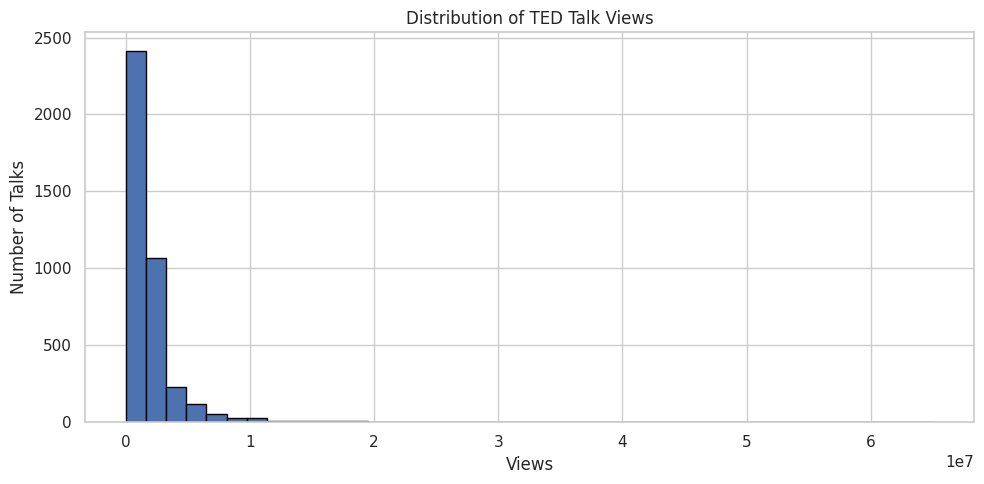

In [21]:
valid_views = df.loc[
    df["views"].notna() & (df["views"] >= 0), "views"
]

plt.figure(figsize=(10, 5))
plt.hist(valid_views, bins=40, edgecolor="black")
plt.title("Distribution of TED Talk Views")
plt.xlabel("Views")
plt.ylabel("Number of Talks")
plt.tight_layout()
plt.show()

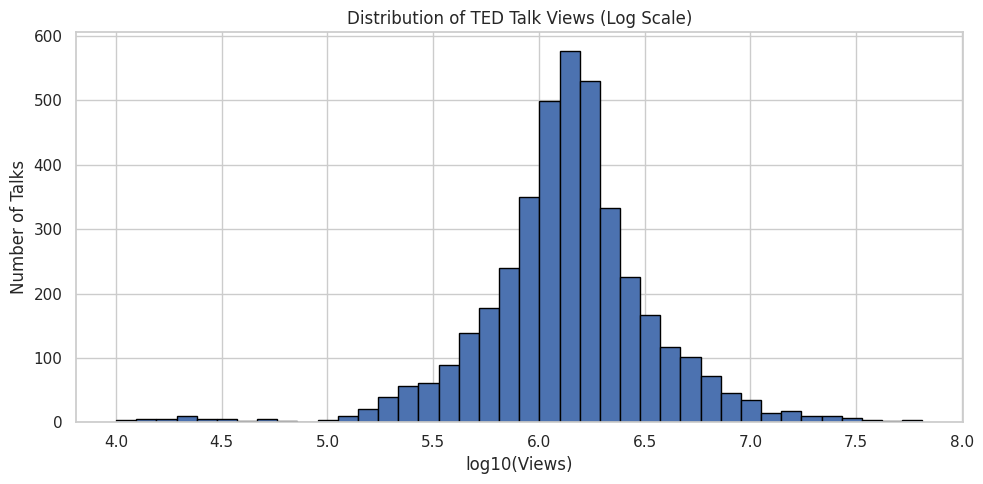

In [22]:
positive_views = valid_views[valid_views > 0]

plt.figure(figsize=(10, 5))
plt.hist(np.log10(positive_views), bins=40, edgecolor="black")
plt.title("Distribution of TED Talk Views (Log Scale)")
plt.xlabel("log10(Views)")
plt.ylabel("Number of Talks")
plt.tight_layout()
plt.show()

In [23]:
views = df["views"].dropna()

Q1 = views.quantile(0.25)
Q3 = views.quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = views[
    (views < lower_limit) | (views > upper_limit)
]

print("Potential view outliers:", len(outliers))
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Outlier percentage:", round(len(outliers) / len(views) * 100, 2), "%")

Potential view outliers: 393
Lower limit: -994492.5
Upper limit: 4009671.5
Outlier percentage: 9.81 %


In [24]:
if "duration" in df.columns:
    df["duration"] = pd.to_numeric(
        df["duration"], errors="coerce"
    )

    print("Missing durations:", df["duration"].isna().sum())
    print("Invalid durations (zero or less):",
          (df["duration"] <= 0).sum())

    print("\nDuration statistics (raw units):")
    print(df["duration"].describe())

Missing durations: 0
Invalid durations (zero or less): 0

Duration statistics (raw units):
count    4005.000000
mean      724.011236
std       361.775462
min        60.000000
25%       393.000000
50%       738.000000
75%       974.000000
max      3922.000000
Name: duration, dtype: float64


Mean duration (minutes): 12.07
Median duration (minutes): 12.3


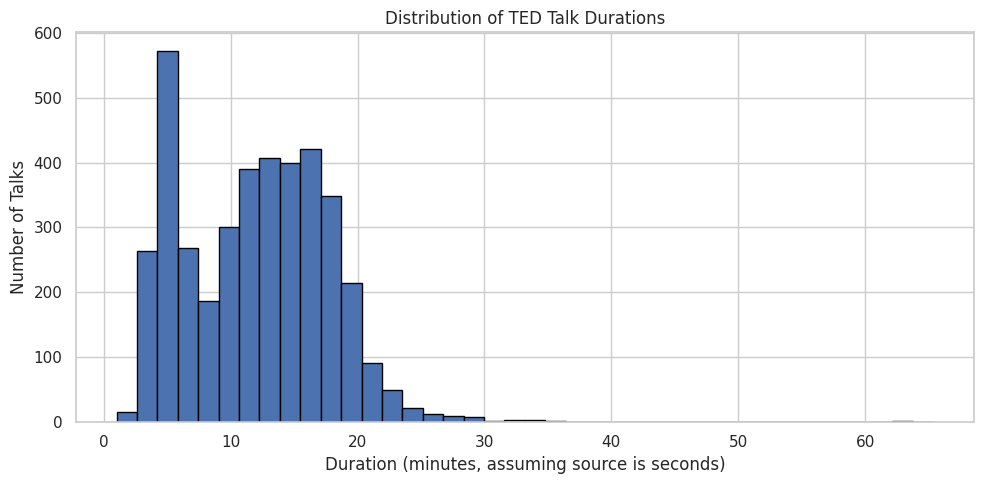

In [25]:
if "duration" in df.columns:
    duration_minutes = df.loc[
        df["duration"] > 0, "duration"
    ] / 60

    print("Mean duration (minutes):",
          round(duration_minutes.mean(), 2))
    print("Median duration (minutes):",
          round(duration_minutes.median(), 2))

    plt.figure(figsize=(10, 5))
    plt.hist(duration_minutes, bins=40, edgecolor="black")
    plt.title("Distribution of TED Talk Durations")
    plt.xlabel("Duration (minutes, assuming source is seconds)")
    plt.ylabel("Number of Talks")
    plt.tight_layout()
    plt.show()

In [26]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Check whether the views column exists
if "views" not in df.columns:
    print("Error: 'views' column not found.")
    print("Available columns:", df.columns.tolist())

else:
    # Convert views to numeric values safely
    df["views"] = pd.to_numeric(df["views"], errors="coerce")

    # Remove missing and negative view counts for analysis
    valid_views = df.loc[
        df["views"].notna() & (df["views"] >= 0)
    ].copy()

    print("Total TED Talks:", len(df))
    print("Valid view records:", len(valid_views))
    print("Missing or invalid view records:",
          df["views"].isna().sum())
    print("\nViews Statistics:")
    print("Mean:", round(valid_views["views"].mean(), 2))
    print("Median:", round(valid_views["views"].median(), 2))
    print("Minimum:", valid_views["views"].min())
    print("Maximum:", valid_views["views"].max())

    # Display the 10 most-viewed talks
    display_columns = [
        col for col in
        ["title", "speaker_1", "views", "topics", "url"]
        if col in valid_views.columns
    ]

    print("\nTop 10 Most-Viewed TED Talks:")
    display(
        valid_views.nlargest(10, "views")[display_columns]
        .reset_index(drop=True)
    )


Total TED Talks: 4005
Valid view records: 4005
Missing or invalid view records: 0

Views Statistics:
Mean: 2148005.57
Median: 1375508.0
Minimum: 0
Maximum: 65051954

Top 10 Most-Viewed TED Talks:


,title,speaker_1,views,topics,url
0,Do schools kill creativity?,Sir Ken Robinson,65051954,"['children', 'creativity', 'culture', 'dance',...",https://www.ted.com/talks/sir_ken_robinson_do_...
1,Your body language may shape who you are,Amy Cuddy,57074270,"['body language', 'brain', 'business', 'psycho...",https://www.ted.com/talks/amy_cuddy_your_body_...
2,This is what happens when you reply to spam email,James Veitch,56932551,"['comedy', 'curiosity', 'communication', 'humo...",https://www.ted.com/talks/james_veitch_this_is...
3,How great leaders inspire action,Simon Sinek,49730580,"['TEDx', 'business', 'entrepreneur', 'leadersh...",https://www.ted.com/talks/simon_sinek_how_grea...
4,The power of vulnerability,Brené Brown,47544833,"['TEDx', 'communication', 'culture', 'depressi...",https://www.ted.com/talks/brene_brown_the_powe...
5,How to speak so that people want to listen,Julian Treasure,41504331,"['culture', 'sound', 'speech']",https://www.ted.com/talks/julian_treasure_how_...
6,Inside the mind of a master procrastinator,Tim Urban,37976820,"['brain', 'comedy', 'decision-making', 'entert...",https://www.ted.com/talks/tim_urban_inside_the...
7,"Looks aren't everything. Believe me, I'm a model.",Cameron Russell,33874546,"['TEDx', 'beauty', 'culture', 'fashion', 'phot...",https://www.ted.com/talks/cameron_russell_look...
8,My philosophy for a happy life,Sam Berns,33691484,"['life', 'happiness', 'personal growth', 'self...",https://www.ted.com/talks/sam_berns_my_philoso...
9,The next outbreak? We're not ready,Bill Gates,33521780,"['disaster relief', 'disease', 'ebola', 'globa...",https://www.ted.com/talks/bill_gates_the_next_...


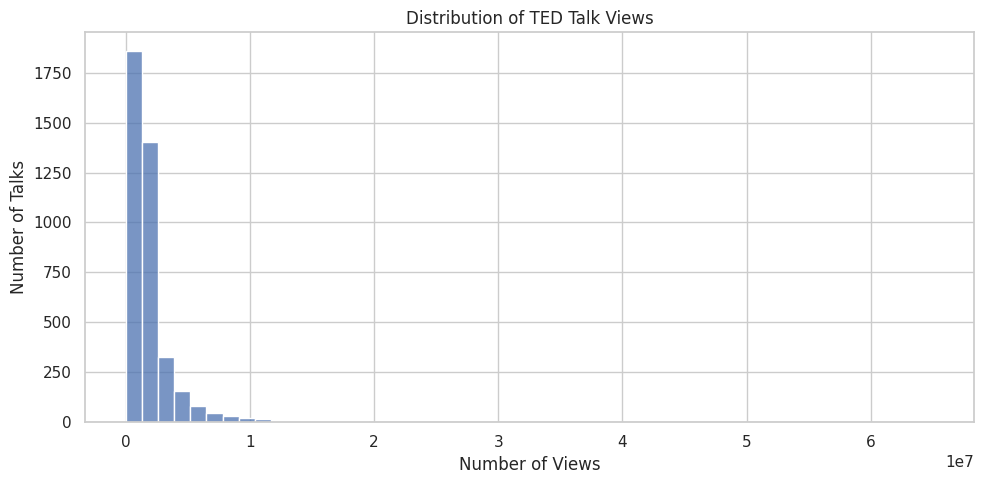

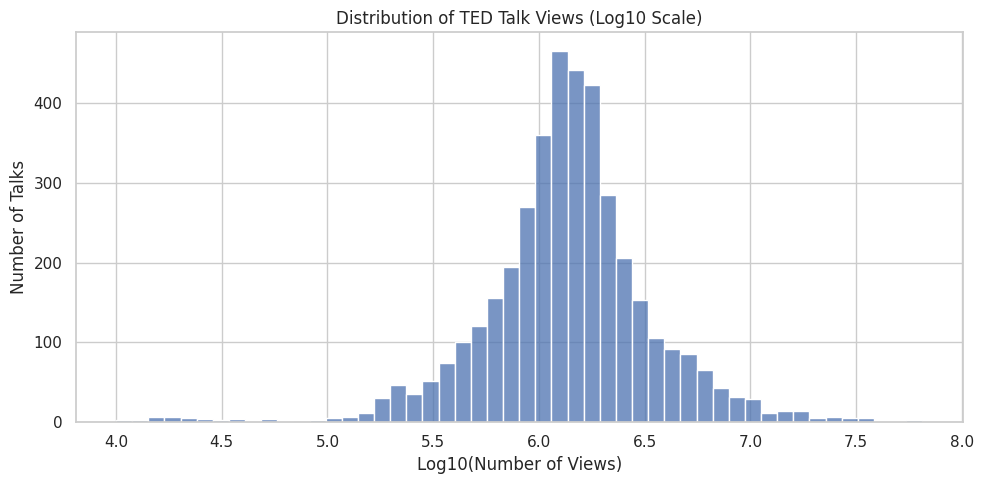

In [27]:

if "views" in df.columns:
    valid_views = df.loc[
        df["views"].notna() & (df["views"] >= 0), "views"
    ]

    if len(valid_views) > 0:
        # Original distribution
        plt.figure(figsize=(10, 5))
        sns.histplot(valid_views, bins=50, kde=False)
        plt.title("Distribution of TED Talk Views")
        plt.xlabel("Number of Views")
        plt.ylabel("Number of Talks")
        plt.tight_layout()
        plt.show()

        # Log-scale distribution
        positive_views = valid_views[valid_views > 0]

        if len(positive_views) > 0:
            plt.figure(figsize=(10, 5))
            sns.histplot(
                np.log10(positive_views),
                bins=50,
                kde=False
            )
            plt.title("Distribution of TED Talk Views (Log10 Scale)")
            plt.xlabel("Log10(Number of Views)")
            plt.ylabel("Number of Talks")
            plt.tight_layout()
            plt.show()
    else:
        print("No valid view counts available for plotting.")


In [28]:

if "views" in df.columns:
    valid_views = df.loc[
        df["views"].notna() & (df["views"] >= 0), "views"
    ]

    if len(valid_views) > 0:
        Q1 = valid_views.quantile(0.25)
        Q3 = valid_views.quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = valid_views[
            (valid_views < lower_bound) |
            (valid_views > upper_bound)
        ]

        print("Q1:", Q1)
        print("Q3:", Q3)
        print("IQR:", IQR)
        print("Upper outlier boundary:", upper_bound)
        print("Potential outlier count:", len(outliers))
        print(
            "Percentage of valid talks classified as outliers:",
            round(len(outliers) / len(valid_views) * 100, 2),
            "%"
        )
    else:
        print("No valid view counts available for outlier analysis.")


Q1: 882069.0
Q3: 2133110.0
IQR: 1251041.0
Upper outlier boundary: 4009671.5
Potential outlier count: 393
Percentage of valid talks classified as outliers: 9.81 %


In [29]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

if "duration" not in df.columns:
    print("Error: 'duration' column not found.")
    print("Available columns:", df.columns.tolist())

else:
    # Convert duration to numeric safely
    df["duration"] = pd.to_numeric(
        df["duration"], errors="coerce"
    )

    total_talks = len(df)
    missing_duration = df["duration"].isna().sum()
    zero_or_negative = (
        df["duration"].notna() & (df["duration"] <= 0)
    ).sum()

    # Keep only positive durations for the main analysis
    valid_duration = df.loc[
        df["duration"].notna() & (df["duration"] > 0)
    ].copy()

    print("DURATION ANALYSIS")
    print("-" * 40)
    print("Total TED Talks:", total_talks)
    print("Missing or non-numeric durations:", missing_duration)
    print("Zero or negative durations:", zero_or_negative)
    print("Valid positive durations:", len(valid_duration))

    if len(valid_duration) > 0:
        # Inspect raw duration values before interpreting their units
        print("\nSample duration values:")
        print(valid_duration["duration"].head(10).tolist())

        print("\nDuration statistics (raw units):")
        print(valid_duration["duration"].describe())

        print("\nMean duration:", round(
            valid_duration["duration"].mean(), 2
        ))
        print("Median duration:", round(
            valid_duration["duration"].median(), 2
        ))
        print("Minimum duration:", valid_duration["duration"].min())
        print("Maximum duration:", valid_duration["duration"].max())

    else:
        print("No valid positive durations found.")


DURATION ANALYSIS
----------------------------------------
Total TED Talks: 4005
Missing or non-numeric durations: 0
Zero or negative durations: 0
Valid positive durations: 4005

Sample duration values:
[977, 1190, 1286, 1116, 1164, 1198, 992, 1485, 1262, 1538]

Duration statistics (raw units):
count    4005.000000
mean      724.011236
std       361.775462
min        60.000000
25%       393.000000
50%       738.000000
75%       974.000000
max      3922.000000
Name: duration, dtype: float64

Mean duration: 724.01
Median duration: 738.0
Minimum duration: 60
Maximum duration: 3922


In [30]:

if "duration" in df.columns:
    valid_duration = df.loc[
        df["duration"].notna() & (df["duration"] > 0)
    ].copy()

    # Convert seconds into minutes
    valid_duration["duration_minutes"] = (
        valid_duration["duration"] / 60
    )

    print("Duration statistics in minutes:")
    print(
        valid_duration["duration_minutes"].describe().round(2)
    )

    print("\nAverage duration:",
          round(valid_duration["duration_minutes"].mean(), 2),
          "minutes")

    print("Median duration:",
          round(valid_duration["duration_minutes"].median(), 2),
          "minutes")

    print("Shortest talk:",
          round(valid_duration["duration_minutes"].min(), 2),
          "minutes")

    print("Longest talk:",
          round(valid_duration["duration_minutes"].max(), 2),
          "minutes")


Duration statistics in minutes:
count    4005.00
mean       12.07
std         6.03
min         1.00
25%         6.55
50%        12.30
75%        16.23
max        65.37
Name: duration_minutes, dtype: float64

Average duration: 12.07 minutes
Median duration: 12.3 minutes
Shortest talk: 1.0 minutes
Longest talk: 65.37 minutes


In [31]:

if "duration" in df.columns:
    valid_duration = df.loc[
        df["duration"].notna() & (df["duration"] > 0)
    ].copy()

    # Assumes duration is stored in seconds
    valid_duration["duration_minutes"] = (
        valid_duration["duration"] / 60
    )

    display_columns = [
        col for col in
        ["title", "speaker_1", "duration_minutes", "views", "url"]
        if col in valid_duration.columns
    ]

    print("10 Shortest TED Talks:")
    display(
        valid_duration.nsmallest(
            10, "duration_minutes"
        )[display_columns].reset_index(drop=True)
    )

    print("\n10 Longest TED Talks:")
    display(
        valid_duration.nlargest(
            10, "duration_minutes"
        )[display_columns].reset_index(drop=True)
    )


10 Shortest TED Talks:


,title,speaker_1,duration_minutes,views,url
0,"""Ode to the Only Black Kid in the Class""",Clint Smith,1.000000,163277,https://www.ted.com/talks/clint_smith_ode_to_t...
1,"""Three Months After""",Cristin O'Keefe Aptowicz,1.300000,133886,https://www.ted.com/talks/cristin_o_keefe_apto...
2,"""New Colossus""",Emma Lazarus,1.300000,142405,https://www.ted.com/talks/emma_lazarus_new_col...
3,"""Illusions for a better society""",Aaron Duffy,1.783333,10356,https://www.ted.com/talks/aaron_duffy_lake_buc...
4,"""The Second Coming""",William Butler Yeats,1.816667,198694,https://www.ted.com/talks/william_butler_yeats...
5,"""To Make Use of Water""",Safia Elhillo,2.033333,230354,https://www.ted.com/talks/safia_elhillo_to_mak...
6,"""The Road Not Taken""",Robert Frost,2.050000,661693,https://www.ted.com/talks/robert_frost_the_roa...
7,The ancestor of language,Murray Gell-Mann,2.250000,953706,https://www.ted.com/talks/murray_gell_mann_the...
8,"""Clonie""",Nellie McKay,2.333333,840407,https://www.ted.com/talks/nellie_mckay_clonie/
9,How the button changed fashion,Isaac Mizrahi,2.333333,530562,https://www.ted.com/talks/isaac_mizrahi_how_th...



10 Longest TED Talks:


,title,speaker_1,duration_minutes,views,url
0,How we can turn the tide on climate,Chris Anderson,65.366667,1493370,https://www.ted.com/talks/christiana_figueres_...
1,The quest for the coronavirus vaccine,Seth Berkley,62.666667,380451,https://www.ted.com/talks/seth_berkley_the_que...
2,It's OK to feel overwhelmed. Here's what to do...,Elizabeth Gilbert,62.333333,1142208,https://www.ted.com/talks/elizabeth_gilbert_it...
3,Nationalism vs. globalism: the new political d...,Yuval Noah Harari,60.133333,3028381,https://www.ted.com/talks/yuval_noah_harari_na...
4,What the world can learn from China's response...,Gary Liu,58.383333,1242418,https://www.ted.com/talks/gary_liu_what_the_wo...
5,What coronavirus means for the global economy,Ray Dalio,52.666667,1579481,https://www.ted.com/talks/ray_dalio_what_coron...
6,How we must respond to the coronavirus pandemic,Bill Gates,51.833333,6144695,https://www.ted.com/talks/bill_gates_how_we_mu...
7,An ethical plan for ending the pandemic and re...,Danielle Allen,50.116667,845628,https://www.ted.com/talks/danielle_allen_an_et...
8,Political common ground in a polarized United ...,Gretchen Carlson,47.550000,1049407,https://www.ted.com/talks/gretchen_carlson_dav...
9,My days as a young rebel,Frank Gehry,44.633333,703868,https://www.ted.com/talks/frank_gehry_my_days_...


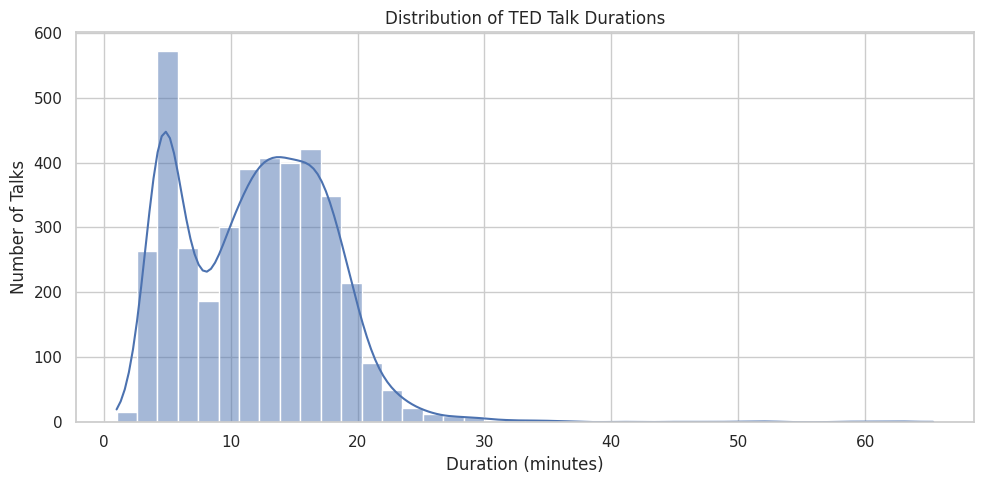

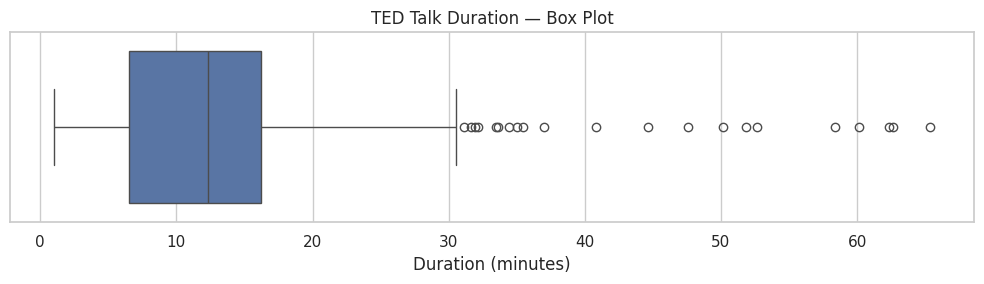

In [32]:

if "duration" in df.columns:
    valid_duration = df.loc[
        df["duration"].notna() & (df["duration"] > 0),
        "duration"
    ]

    if len(valid_duration) > 0:
        # Assumes seconds
        duration_minutes = valid_duration / 60

        plt.figure(figsize=(10, 5))
        sns.histplot(
            duration_minutes,
            bins=40,
            kde=True
        )

        plt.title("Distribution of TED Talk Durations")
        plt.xlabel("Duration (minutes)")
        plt.ylabel("Number of Talks")
        plt.tight_layout()
        plt.show()

        # Box plot to inspect the spread and potential outliers
        plt.figure(figsize=(10, 3))
        sns.boxplot(x=duration_minutes)

        plt.title("TED Talk Duration — Box Plot")
        plt.xlabel("Duration (minutes)")
        plt.tight_layout()
        plt.show()
    else:
        print("No valid duration values available for plotting.")


In [33]:

if "duration" in df.columns:
    valid_duration = df.loc[
        df["duration"].notna() & (df["duration"] > 0),
        "duration"
    ]

    if len(valid_duration) > 0:
        Q1 = valid_duration.quantile(0.25)
        Q3 = valid_duration.quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = valid_duration[
            (valid_duration < lower_bound) |
            (valid_duration > upper_bound)
        ]

        print("Q1:", Q1)
        print("Q3:", Q3)
        print("IQR:", IQR)
        print("Lower boundary:", lower_bound)
        print("Upper boundary:", upper_bound)
        print("Potential outliers:", len(outliers))

        print(
            "Outlier percentage:",
            round(len(outliers) / len(valid_duration) * 100, 2),
            "%"
        )
    else:
        print("No valid duration values for outlier analysis.")


Q1: 393.0
Q3: 974.0
IQR: 581.0
Lower boundary: -478.5
Upper boundary: 1845.5
Potential outliers: 21
Outlier percentage: 0.52 %


Spearman correlation between duration and views: 0.1083


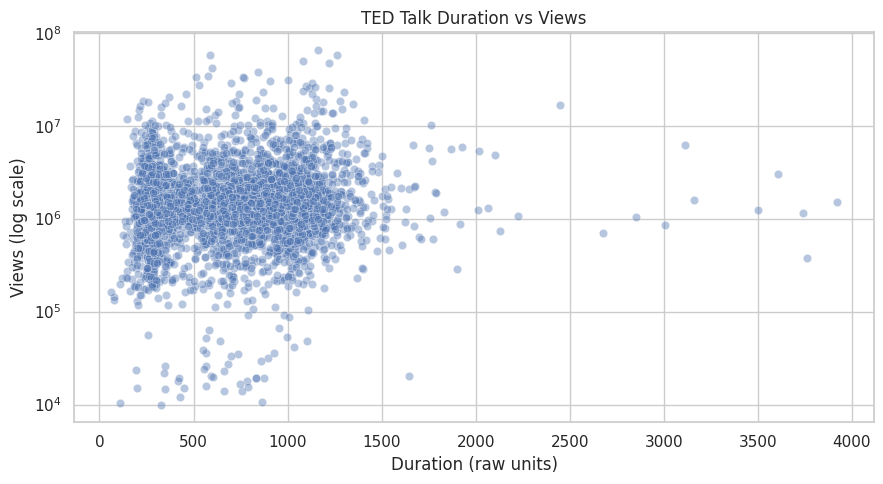

In [34]:

if "duration" in df.columns and "views" in df.columns:
    duration_views = df[["duration", "views"]].copy()

    duration_views["duration"] = pd.to_numeric(
        duration_views["duration"], errors="coerce"
    )
    duration_views["views"] = pd.to_numeric(
        duration_views["views"], errors="coerce"
    )

    duration_views = duration_views.dropna()
    duration_views = duration_views[
        (duration_views["duration"] > 0) &
        (duration_views["views"] >= 0)
    ]

    if len(duration_views) >= 2:
        correlation = duration_views[
            ["duration", "views"]
        ].corr(method="spearman").iloc[0, 1]

        print("Spearman correlation between duration and views:",
              round(correlation, 4))

        plt.figure(figsize=(9, 5))
        sns.scatterplot(
            data=duration_views,
            x="duration",
            y="views",
            alpha=0.4
        )

        plt.yscale("log")
        plt.title("TED Talk Duration vs Views")
        plt.xlabel("Duration (raw units)")
        plt.ylabel("Views (log scale)")
        plt.tight_layout()
        plt.show()
    else:
        print("Not enough valid records for correlation analysis.")


In [35]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

for col in ["recorded_date", "published_date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce", utc=True)

        print("\n", col)
        print("Missing or invalid dates:", df[col].isna().sum())
        print("Earliest date:", df[col].min())
        print("Latest date:", df[col].max())



 recorded_date
Missing or invalid dates: 1
Earliest date: 1984-02-02 00:00:00+00:00
Latest date: 2020-04-30 00:00:00+00:00

 published_date
Missing or invalid dates: 0
Earliest date: 2006-06-27 00:00:00+00:00
Latest date: 2020-04-30 00:00:00+00:00


Talks published each year:


,number_of_talks
published_year,
2006,49
2007,119
2008,185
2009,215
2010,230
2011,255
2012,303
2013,242
2014,240


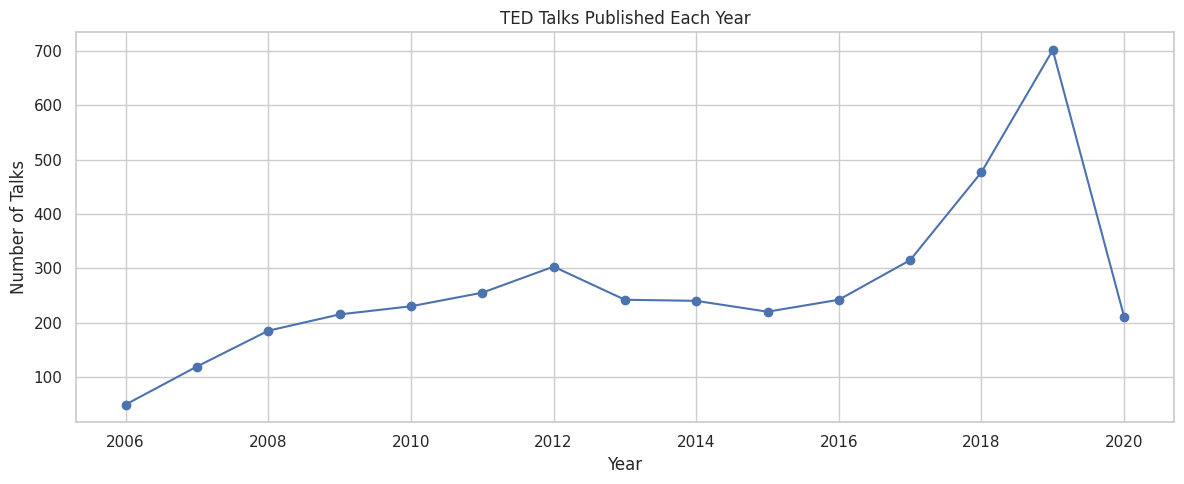

In [36]:

if "published_date" in df.columns:
    published = df.dropna(subset=["published_date"]).copy()

    published["published_year"] = (
        published["published_date"].dt.year
    )

    yearly_talks = published["published_year"].value_counts().sort_index()

    print("Talks published each year:")
    display(yearly_talks.rename("number_of_talks").to_frame())

    plt.figure(figsize=(12, 5))
    yearly_talks.plot(kind="line", marker="o")
    plt.title("TED Talks Published Each Year")
    plt.xlabel("Year")
    plt.ylabel("Number of Talks")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


Missing native languages: 0

Top 10 native languages:
native_lang
en       3957
es         27
fr          9
ja          3
hi          2
de          1
pt          1
ko          1
pt-br       1
ar          1
Name: count, dtype: int64


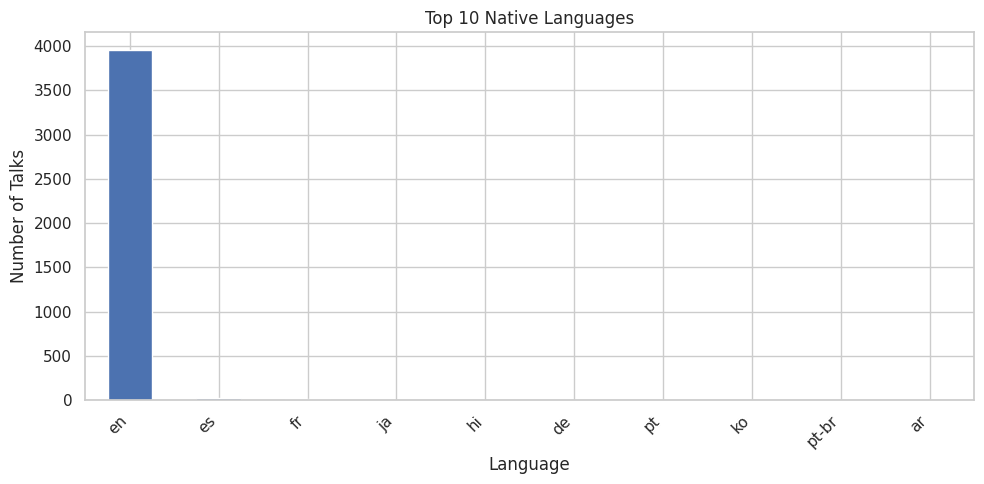

In [37]:

if "native_lang" in df.columns:
    native = df["native_lang"].fillna("").astype(str).str.strip()

    print("Missing native languages:", native.eq("").sum())
    print("\nTop 10 native languages:")
    print(native[native != ""].value_counts().head(10))

    native[native != ""].value_counts().head(10).plot(
        kind="bar", figsize=(10, 5)
    )
    plt.title("Top 10 Native Languages")
    plt.xlabel("Language")
    plt.ylabel("Number of Talks")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


In [38]:

import ast

def parse_list_column(value):
    if isinstance(value, (list, tuple, set)):
        return list(value)

    if not isinstance(value, str) or not value.strip():
        return []

    try:
        parsed = ast.literal_eval(value)
        if isinstance(parsed, (list, tuple, set)):
            return list(parsed)
        if isinstance(parsed, str):
            return [parsed]
    except (ValueError, SyntaxError):
        pass

    return [item.strip() for item in value.split(",") if item.strip()]

if "available_lang" in df.columns:
    df["available_lang_list"] = df["available_lang"].apply(
        parse_list_column
    )

    df["available_lang_count"] = df["available_lang_list"].apply(
        lambda languages: len([
            str(lang).strip().lower()
            for lang in languages
            if str(lang).strip()
        ])
    )

    all_languages = (
        df["available_lang_list"]
        .explode()
        .dropna()
        .astype(str)
        .str.strip()
        .str.lower()
    )

    all_languages = all_languages[all_languages != ""]

    print("Talks with no available-language entries:",
          (df["available_lang_count"] == 0).sum())

    print("\nTop 10 available languages:")
    print(all_languages.value_counts().head(10))

    print("\nLanguages per talk:")
    print(df["available_lang_count"].describe())


Talks with no available-language entries: 0

Top 10 available languages:
available_lang_list
en       4005
es       3915
pt-br    3899
fr       3863
ar       3841
zh-tw    3818
zh-cn    3788
ko       3755
ru       3676
tr       3610
Name: count, dtype: int64

Languages per talk:
count    4005.000000
mean       25.304120
std         9.038567
min         1.000000
25%        20.000000
50%        25.000000
75%        31.000000
max        73.000000
Name: available_lang_count, dtype: float64


In [39]:

import ast

def parse_list_column(value):
    if isinstance(value, (list, tuple, set)):
        return list(value)

    if not isinstance(value, str) or not value.strip():
        return []

    try:
        parsed = ast.literal_eval(value)
        if isinstance(parsed, (list, tuple, set)):
            return list(parsed)
        if isinstance(parsed, str):
            return [parsed]
    except (ValueError, SyntaxError):
        pass

    return [item.strip() for item in value.split(",") if item.strip()]

if "available_lang" in df.columns:
    df["available_lang_list"] = df["available_lang"].apply(
        parse_list_column
    )

    df["available_lang_count"] = df["available_lang_list"].apply(
        lambda languages: len([
            str(lang).strip().lower()
            for lang in languages
            if str(lang).strip()
        ])
    )

    all_languages = (
        df["available_lang_list"]
        .explode()
        .dropna()
        .astype(str)
        .str.strip()
        .str.lower()
    )

    all_languages = all_languages[all_languages != ""]

    print("Talks with no available-language entries:",
          (df["available_lang_count"] == 0).sum())

    print("\nTop 10 available languages:")
    print(all_languages.value_counts().head(10))

    print("\nLanguages per talk:")
    print(df["available_lang_count"].describe())


Talks with no available-language entries: 0

Top 10 available languages:
available_lang_list
en       4005
es       3915
pt-br    3899
fr       3863
ar       3841
zh-tw    3818
zh-cn    3788
ko       3755
ru       3676
tr       3610
Name: count, dtype: int64

Languages per talk:
count    4005.000000
mean       25.304120
std         9.038567
min         1.000000
25%        20.000000
50%        25.000000
75%        31.000000
max        73.000000
Name: available_lang_count, dtype: float64


Unique events: 459

Top 10 events:
event
TED-Ed            556
TED2017            96
TED2018            96
TED2019            91
TED2014            84
TED2009            81
TED2016            75
TED2015            75
TED2013            75
TEDGlobal 2012     70
Name: count, dtype: int64


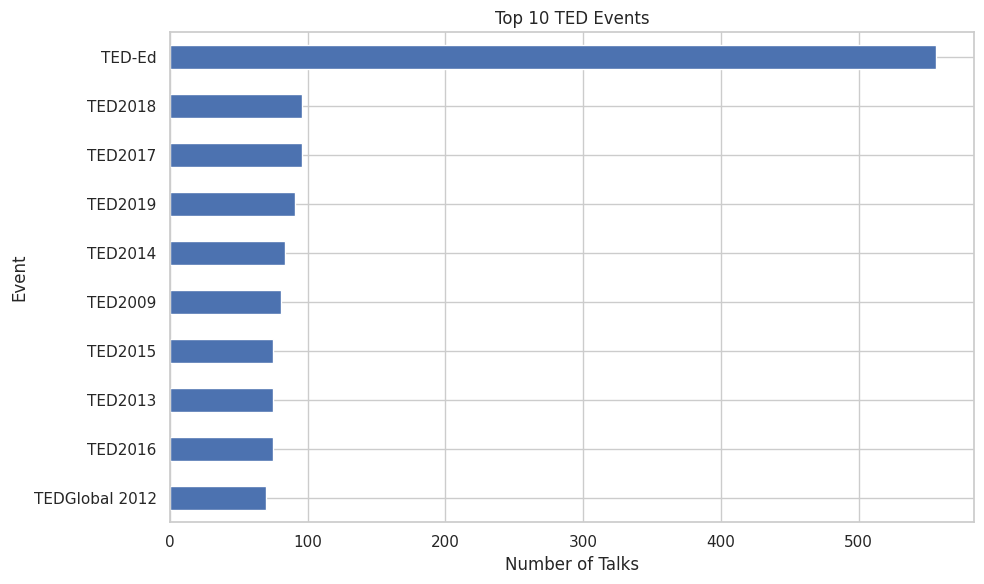

In [40]:

if "event" in df.columns:
    events = df["event"].fillna("").astype(str).str.strip()
    events = events[events != ""]

    print("Unique events:", events.nunique())
    print("\nTop 10 events:")
    print(events.value_counts().head(10))

    events.value_counts().head(10).sort_values().plot(
        kind="barh", figsize=(10, 6)
    )
    plt.title("Top 10 TED Events")
    plt.xlabel("Number of Talks")
    plt.ylabel("Event")
    plt.tight_layout()
    plt.show()


Unique occupations: 2231

Top 10 occupations:
occupations
'author']}               70
{0: ['writer']}          53
'activist']}             51
{0: ['author'            49
{0: ['journalist']}      47
{0: ['writer'            44
{0: ['entrepreneur']}    42
{0: ['artist']}          41
{0: ['architect']}       38
'entrepreneur']}         37
Name: count, dtype: int64


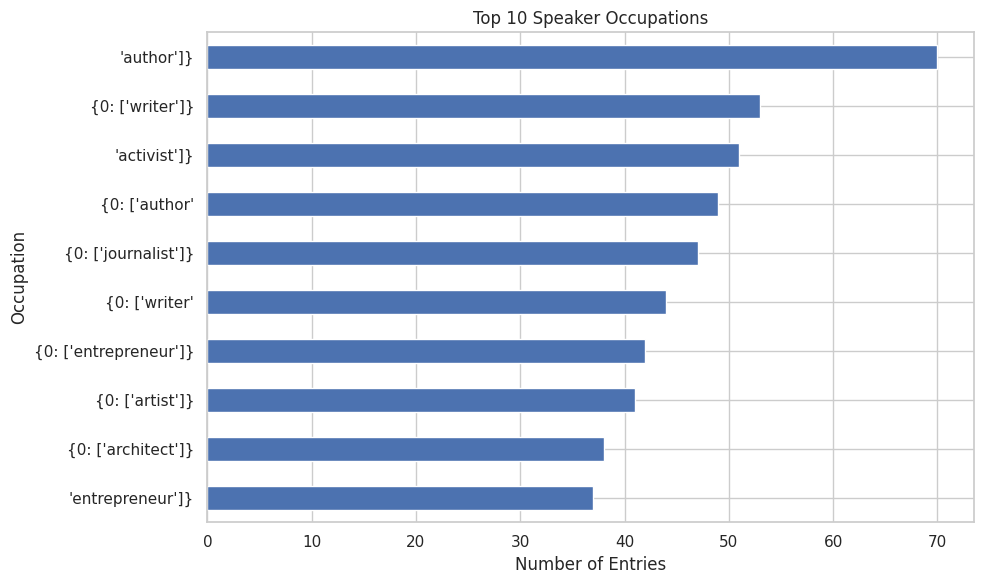

In [41]:

if "occupations" in df.columns:
    occupation_lists = df["occupations"].apply(parse_list_column)

    occupation_counts = (
        occupation_lists
        .explode()
        .dropna()
        .astype(str)
        .str.strip()
    )

    occupation_counts = occupation_counts[
        occupation_counts != ""
    ].value_counts()

    print("Unique occupations:", len(occupation_counts))
    print("\nTop 10 occupations:")
    print(occupation_counts.head(10))

    occupation_counts.head(10).sort_values().plot(
        kind="barh", figsize=(10, 6)
    )
    plt.title("Top 10 Speaker Occupations")
    plt.xlabel("Number of Entries")
    plt.ylabel("Occupation")
    plt.tight_layout()
    plt.show()


In [42]:

if "comments" in df.columns:
    df["comments"] = pd.to_numeric(
        df["comments"], errors="coerce"
    )

    valid_comments = df.loc[
        df["comments"].notna() & (df["comments"] >= 0)
    ].copy()

    print("Missing or invalid comments:", df["comments"].isna().sum())
    print("Valid comment records:", len(valid_comments))

    if len(valid_comments) > 0:
        print("\nComment statistics:")
        print(valid_comments["comments"].describe())

        display_cols = [
            col for col in
            ["title", "speaker_1", "comments", "views", "url"]
            if col in df.columns
        ]

        print("\nTop 10 most-commented talks:")
        display(
            valid_comments.nlargest(10, "comments")[display_cols]
            .reset_index(drop=True)
        )


Missing or invalid comments: 655
Valid comment records: 3350

Comment statistics:
count    3350.000000
mean      161.997015
std       268.838922
min         0.000000
25%        38.000000
50%        89.000000
75%       188.000000
max      6449.000000
Name: comments, dtype: float64

Top 10 most-commented talks:


,title,speaker_1,comments,views,url
0,Militant atheism,Richard Dawkins,6449.0,5788514,https://www.ted.com/talks/richard_dawkins_mili...
1,Do schools kill creativity?,Sir Ken Robinson,4931.0,65051954,https://www.ted.com/talks/sir_ken_robinson_do_...
2,Science can answer moral questions,Sam Harris,3424.0,6331825,https://www.ted.com/talks/sam_harris_science_c...
3,How do you explain consciousness?,David Chalmers,3006.0,2910843,https://www.ted.com/talks/david_chalmers_how_d...
4,My stroke of insight,Jill Bolte Taylor,2984.0,26553231,https://www.ted.com/talks/jill_bolte_taylor_my...
5,Your body language may shape who you are,Amy Cuddy,2633.0,57074270,https://www.ted.com/talks/amy_cuddy_your_body_...
6,Taking imagination seriously,Janet Echelman,2529.0,2297341,https://www.ted.com/talks/janet_echelman_takin...
7,On reading the Koran,Lesley Hazleton,2463.0,2269271,https://www.ted.com/talks/lesley_hazleton_on_r...
8,The danger of science denial,Michael Specter,2366.0,2170700,https://www.ted.com/talks/michael_specter_the_...
9,The power of vulnerability,Brené Brown,2209.0,47544833,https://www.ted.com/talks/brene_brown_the_powe...


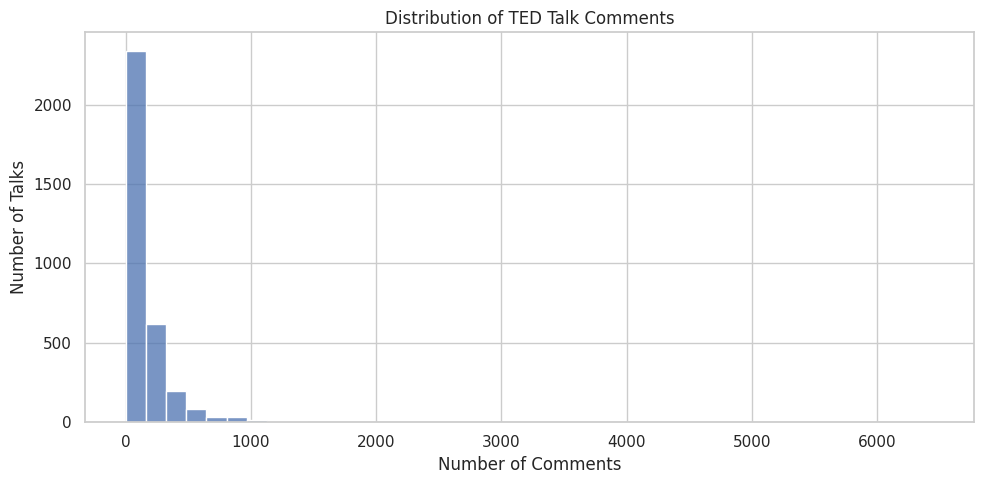

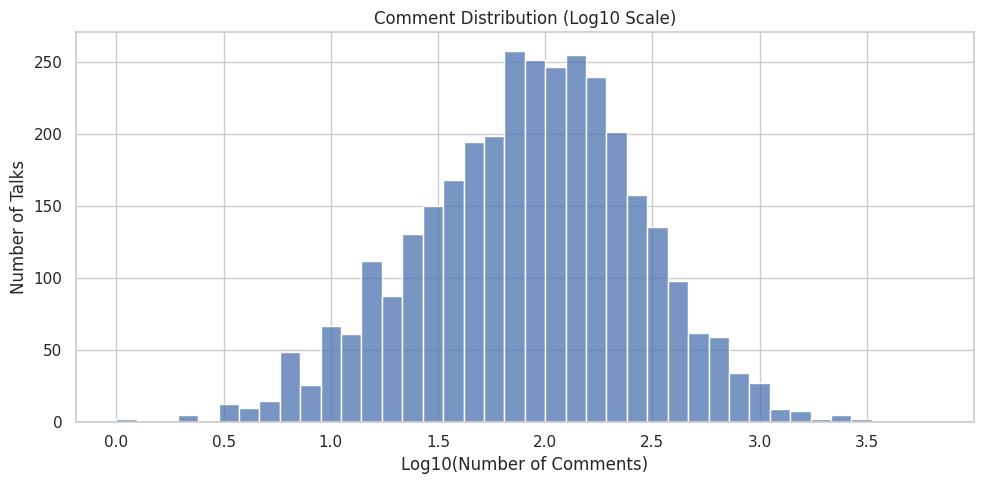

In [43]:

if "comments" in df.columns:
    valid_comments = df.loc[
        df["comments"].notna() & (df["comments"] >= 0),
        "comments"
    ]

    if len(valid_comments) > 0:
        plt.figure(figsize=(10, 5))
        sns.histplot(valid_comments, bins=40)
        plt.title("Distribution of TED Talk Comments")
        plt.xlabel("Number of Comments")
        plt.ylabel("Number of Talks")
        plt.tight_layout()
        plt.show()

        positive_comments = valid_comments[valid_comments > 0]

        if len(positive_comments) > 0:
            plt.figure(figsize=(10, 5))
            sns.histplot(np.log10(positive_comments), bins=40)
            plt.title("Comment Distribution (Log10 Scale)")
            plt.xlabel("Log10(Number of Comments)")
            plt.ylabel("Number of Talks")
            plt.tight_layout()
            plt.show()


In [44]:

if "comments" in df.columns:
    valid_comments = df.loc[
        df["comments"].notna() & (df["comments"] >= 0),
        "comments"
    ]

    if len(valid_comments) > 0:
        q1 = valid_comments.quantile(0.25)
        q3 = valid_comments.quantile(0.75)
        iqr = q3 - q1
        upper_bound = q3 + 1.5 * iqr

        outliers = valid_comments[valid_comments > upper_bound]

        print("Mean:", valid_comments.mean())
        print("Median:", valid_comments.median())
        print("Minimum:", valid_comments.min())
        print("Maximum:", valid_comments.max())
        print("Upper outlier boundary:", upper_bound)
        print("Potential high-comment outliers:", len(outliers))


Mean: 161.99701492537312
Median: 89.0
Minimum: 0.0
Maximum: 6449.0
Upper outlier boundary: 413.0
Potential high-comment outliers: 261


In [45]:

if "related_talks" in df.columns:
    print("Sample related_talks values:")
    display(df[["title", "related_talks"]].head(10))

    print("\nMissing related_talks entries:",
          df["related_talks"].isna().sum())
else:
    print("'related_talks' column not found.")


Sample related_talks values:


,title,related_talks
0,Averting the climate crisis,"{243: 'New thinking on the climate crisis', 54..."
1,The best stats you've ever seen,"{2056: ""Own your body's data"", 2296: 'A visual..."
2,Simplicity sells,"{1725: '10 top time-saving tech tips', 2274: '..."
3,Greening the ghetto,{1041: '3 stories of local eco-entrepreneurshi...
4,Do schools kill creativity?,"{865: 'Bring on the learning revolution!', 173..."
5,Behind the design of Seattle's library,{750: 'Building a theater that remakes itself'...
6,Letting go of God,"{22: 'Why people believe weird things', 94: ""L..."
7,Let's teach religion -- all religion -- in sch...,"{71: 'A life of purpose', 2011: 'Is religion g..."
8,A life of purpose,"{94: ""Let's teach religion -- all religion -- ..."
9,My wish: A global day of film,{2228: 'How virtual reality can create the ult...



Missing related_talks entries: 0


In [46]:

if "related_talks" in df.columns:
    df["related_talks_list"] = df["related_talks"].apply(
        parse_list_column
    )

    df["related_talks_count"] = df["related_talks_list"].apply(
        len
    )

    print("Related-talk count statistics:")
    print(df["related_talks_count"].describe())

    print("\nTalks with the most related-talk entries:")
    display(
        df.nlargest(10, "related_talks_count")[
            ["title", "related_talks_count", "related_talks"]
        ]
    )


Related-talk count statistics:
count    4005.000000
mean        6.491885
std         0.860817
min         1.000000
25%         6.000000
50%         6.000000
75%         7.000000
max        12.000000
Name: related_talks_count, dtype: float64

Talks with the most related-talk entries:


,title,related_talks_count,related_talks
3653,The Prison Break,12,"{50755: 'The Resistance | Think Like A Coder, ..."
3675,The Resistance,12,{52811: 'The Furnace Bots | Think Like A Coder...
3733,The Furnace Bots,12,"{54352: 'The Train Heist | Think Like A Coder,..."
3760,The Train Heist,12,"{56535: 'The Artists | Think Like A Coder, Ep ..."
3808,The Artists,12,"{58017: 'The Chasm | Think Like A Coder, Ep 6'..."
3844,The Chasm,12,{60063: 'The Tower of Epiphany | Think Like A ...
3914,The Tower of Epiphany,12,"{62406: 'The Gauntlet | Think Like A Coder, Ep..."
3988,The Gauntlet,12,{60063: 'The Tower of Epiphany | Think Like A ...
293,"Playtime with Pleo, your robotic dinosaur friend",11,{280: 'Robots inspired by cockroach ingenuity'...
585,"Weird, or just different?",11,"{485: 'Cute, sexy, sweet, funny', 121: 'The gh..."


In [47]:

if "related_talks_list" in df.columns and "talk_id" in df.columns:
    known_ids = set(
        pd.to_numeric(df["talk_id"], errors="coerce")
        .dropna()
        .astype(int)
    )

    reference_ids = []

    for items in df["related_talks_list"]:
        for item in items:
            try:
                reference_ids.append(int(item))
            except (ValueError, TypeError):
                continue

    valid_references = sum(
        ref_id in known_ids for ref_id in reference_ids
    )

    print("Total parsed numeric references:", len(reference_ids))
    print("References found in dataset:", valid_references)
    print("References not found in dataset:",
          len(reference_ids) - valid_references)


Total parsed numeric references: 0
References found in dataset: 0
References not found in dataset: 0


In [49]:

# Check duplicate rows safely, including columns containing lists

df_check = df.copy()

# Convert list/dictionary/set values into comparable strings
def make_hashable(value):
    if isinstance(value, (list, tuple)):
        return tuple(make_hashable(x) for x in value)
    elif isinstance(value, dict):
        return tuple(sorted(
            (str(k), make_hashable(v)) for k, v in value.items()
        ))
    elif isinstance(value, set):
        return tuple(sorted(
            (make_hashable(x) for x in value), key=str
        ))
    else:
        return value

for col in df_check.columns:
    df_check[col] = df_check[col].apply(make_hashable)

print("Exact duplicate rows:", df_check.duplicated().sum())

if "talk_id" in df.columns:
    print(
        "Rows with duplicate talk IDs:",
        df["talk_id"].duplicated(keep=False).sum()
    )
    print(
        "Number of duplicated talk IDs:",
        df["talk_id"].duplicated().sum()
    )


Exact duplicate rows: 0
Rows with duplicate talk IDs: 0
Number of duplicated talk IDs: 0


In [50]:

print("=" * 45)
print("FINAL TED TALKS EDA SUMMARY")
print("=" * 45)

print("Dataset shape:", df.shape)

print("\nMissing values:")
display(
    df.isna().sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

print("\nExact duplicate rows:", df_check.duplicated().sum())

if "talk_id" in df.columns:
    print(
        "Rows with duplicate talk IDs:",
        df["talk_id"].duplicated(keep=False).sum()
    )

if "title" in df.columns:
    print("Unique titles:", df["title"].nunique())
    print("Empty titles:", df["title"].astype(str).str.strip().eq("").sum())

if "combined_text" in df.columns:
    print(
        "Empty combined-text rows:",
        df["combined_text"].astype(str).str.strip().eq("").sum()
    )

print("\nColumns available for recommendation:")
print([
    col for col in
    ["title", "topics", "description", "transcript", "combined_text"]
    if col in df.columns
])

# Save the summary
summary_df = pd.DataFrame({
    "Column": df.columns,
    "Missing Values": [df[col].isna().sum() for col in df.columns]
})

summary_df.to_csv(
    "/content/ted_final_eda_findings.csv",
    index=False
)

print("\nEDA summary saved successfully.")


FINAL TED TALKS EDA SUMMARY
Dataset shape: (4005, 30)

Missing values:


,missing_count
comments,655
occupations,522
all_speakers,4
recorded_date,1
title,0
talk_id,0
about_speakers,0
speaker_1,0
published_date,0
views,0



Exact duplicate rows: 0
Rows with duplicate talk IDs: 0
Unique titles: 4005
Empty titles: 0
Empty combined-text rows: 0

Columns available for recommendation:
['title', 'topics', 'description', 'transcript', 'combined_text']

EDA summary saved successfully.


In [51]:

import os
import ast
import pandas as pd
import numpy as np

print("=" * 55)
print("FINAL EDA VALIDATION")
print("=" * 55)

# 1. TEXT QUALITY CHECKS
print("\n1. TEXT QUALITY")

for col in ["title", "description", "transcript", "about_speakers"]:
    if col in df.columns:
        text = df[col].fillna("").astype(str).str.strip()
        word_count = text.str.split().str.len()

        print(f"\n{col}")
        print("Empty entries:", (text == "").sum())
        print("Unusually short entries (< 10 words):",
              (word_count < 10).sum())
        print("Long entries (> 5000 words):",
              (word_count > 5000).sum())

# 2. SPEAKER COUNTS
print("\n2. SPEAKER CHECK")
if "speaker_1" in df.columns:
    print("Unique primary speakers:", df["speaker_1"].nunique())

if "all_speakers" in df.columns:
    print("Missing all_speakers entries:",
          df["all_speakers"].isna().sum())

# 3. DURATION VALIDATION
print("\n3. DURATION CHECK")
if "duration" in df.columns:
    duration = pd.to_numeric(df["duration"], errors="coerce")
    print("Values that are missing or non-numeric:",
          duration.isna().sum())
    print("Zero or negative durations:",
          (duration <= 0).sum())
    print("Duration minimum:", duration.min())
    print("Duration maximum:", duration.max())

# 4. LANGUAGE CONSISTENCY
print("\n4. LANGUAGE CHECK")
if "native_lang" in df.columns:
    languages = df["native_lang"].dropna().astype(str).str.strip()
    print("Unique native-language values:", languages.nunique())
    print("Blank native-language values:", (languages == "").sum())
    print("Most common languages:")
    print(languages.value_counts().head(10))

if "available_lang_count" in df.columns:
    print("\nAvailable languages per talk:")
    print(df["available_lang_count"].describe())

# 5. RELATED TALK REFERENCES
print("\n5. RELATED TALKS CHECK")

def parse_related(value):
    if isinstance(value, (list, tuple, set)):
        return list(value)

    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)
            if isinstance(parsed, (list, tuple, set)):
                return list(parsed)
        except (ValueError, SyntaxError):
            pass

        return [x.strip() for x in value.split(",") if x.strip()]

    return []

if "related_talks" in df.columns and "talk_id" in df.columns:
    known_ids = set(df["talk_id"].dropna().astype(str).str.strip())
    related_lists = df["related_talks"].apply(parse_related)

    references = [
        str(item).strip()
        for items in related_lists
        for item in items
        if str(item).strip()
    ]

    print("Total related-talk references:", len(references))
    print("References matching dataset talk IDs:",
          sum(ref in known_ids for ref in references))
    print("References not matching dataset talk IDs:",
          sum(ref not in known_ids for ref in references))

    print("Note: Confirm that related_talks contains IDs,")
    print("not URLs or another reference format, before interpreting this.")

# 6. MISSING AND BLANK VALUES
print("\n6. DATA QUALITY CHECK")
print("Rows:", len(df))
print("Duplicate talk IDs:",
      df["talk_id"].duplicated().sum() if "talk_id" in df.columns else "N/A")

print("\nMissing values in original columns:")
original_cols = [
    "title", "speaker_1", "topics", "description",
    "transcript", "views", "duration", "recorded_date",
    "published_date", "native_lang", "available_lang",
    "comments", "occupations", "related_talks"
]
print(df[[c for c in original_cols if c in df.columns]].isna().sum())

# 7. SAVE THE FINAL DATASET
output_path = "/content/ted_talks_eda_ready.csv"
df.to_csv(output_path, index=False)

print("\n7. FINAL DATASET")
print("Saved to:", output_path)
print("File exists:", os.path.exists(output_path))
print("Final dataset shape:", df.shape)
print("\nEDA validation completed!")


FINAL EDA VALIDATION

1. TEXT QUALITY

title
Empty entries: 0
Unusually short entries (< 10 words): 3470
Long entries (> 5000 words): 0

description
Empty entries: 0
Unusually short entries (< 10 words): 1
Long entries (> 5000 words): 0

transcript
Empty entries: 0
Unusually short entries (< 10 words): 7
Long entries (> 5000 words): 22

about_speakers
Empty entries: 503
Unusually short entries (< 10 words): 555
Long entries (> 5000 words): 0

2. SPEAKER CHECK
Unique primary speakers: 3274
Missing all_speakers entries: 4

3. DURATION CHECK
Values that are missing or non-numeric: 0
Zero or negative durations: 0
Duration minimum: 60
Duration maximum: 3922

4. LANGUAGE CHECK
Unique native-language values: 12
Blank native-language values: 0
Most common languages:
native_lang
en       3957
es         27
fr          9
ja          3
hi          2
de          1
pt          1
ko          1
pt-br       1
ar          1
Name: count, dtype: int64

Available languages per talk:
count    4005.000000
m